# Expectations and nested aggregation

<div class="alert alert-info">

**Summary**

This lesson constructs a savings stage whose value takes two expectations, one inside the other, and reads how the package states each, their order, and the maps around them. You will ask the stage's decision [[builder]] for its operations, the inputs and outputs of its two sub-builders, the distribution each expectation integrates, the maps around them, a drawing and its full statement, and read, for contrast, a single expectation over two shocks. The object inspected is the decision builder of the [[elaborated_stage|elaborated stage]]. The lesson constructs only; nothing is evaluated or solved.

</div>

<div class="alert alert-success">

**Relationship with other documents**

**Builds on** — [Value functions and the backward builders](../getting-started/02-value-functions.ipynb) and [Distributions and the forward builders](../getting-started/03-distributions.ipynb): backward builders and declared distributions.

**Formal account** — [Stages and perches](../../docs/bellman-calculus/03-Stages%20and%20perches.md), sections [2.3a](../../docs/bellman-calculus/03-Stages%20and%20perches.md#23a-aggregation-inside-and-outside-the-integral), maps applied inside and outside an expectation, and [2.7](../../docs/bellman-calculus/03-Stages%20and%20perches.md#27-the-forward-builders), the forward builders paired with it.

**See also** — [Smooth-ambiguity savings](../../applications/smooth-ambiguity-savings/declaration/stages/sa_savings/sa_savings.md): the stage's model and its sources.

</div>

<div class="alert">

**Key terminology**

| Term | Meaning |
|---|---|
| [[sub_builder\|sub-builder]] | An operator inside a builder with inputs and outputs of its own. |
| [[aggregation]] | The operation that applies a map $G$ at each point. |
| kernel | The mathematical data an operation uses: a law of motion for a pullback or a push-forward, a value aggregator for an aggregation, a probability distribution for an expectation. |
| card | The printed statement of what a piece of a stage denotes. |

</div>

In this [[stage]] the household arrives with resources $\mathrm m$. At the decision it chooses consumption $\mathrm c$ with $0 < \mathrm c < \mathrm m_d$ and invests the rest in one risky asset, whose gross return $\Psi$ is drawn after the choice; it carries wealth $\mathrm a = (\mathrm m_d - \mathrm c)\Psi$ to the continuation perch. The logarithm of $\Psi$ is normal with mean $\nu$, and the household does not know $\nu$: its belief is $\nu \sim N(\kappa_1, \sigma_\nu^2)$. Its risk aversion $\gamma$ applies to risk, the draw of $\Psi$ at a known $\nu$, and its ambiguity aversion $\eta \ge \gamma$ to ambiguity, the uncertainty about $\nu$. This is the smooth model of ambiguity of Klibanoff, Marinacci and Mukerji (2005, "A smooth model of decision making under ambiguity", *Econometrica*) within recursive utility, as in Ju and Miao (2012, "Ambiguity, learning, and asset returns", *Econometrica*). A **certainty equivalent** is the sure amount a household with that curvature values equally with the random amount, and the value takes two in turn:

$$
\mathit{CE}(\mathrm m_d, \nu) = \mathbb E\bigl[V_\succ(\mathrm a)^{1-\gamma} \mid \nu\bigr]^{1/(1-\gamma)}, \qquad
\mathit{AMB}(\mathrm m_d) = \mathbb E_\nu\bigl[\mathit{CE}(\mathrm m_d, \nu)^{1-\eta}\bigr]^{1/(1-\eta)},
$$

$$
V(\mathrm m_d) = \bigl((1-\beta)\,\mathrm c^{1-\rho} + \beta\,\mathit{AMB}(\mathrm m_d)^{1-\rho}\bigr)^{1/(1-\rho)}.
$$

| In the file | Symbol | Meaning |
|---|---|---|
| `m`, `m_d` | $\mathrm m$, $\mathrm m_d$ | resources on arrival and at the decision, equal to each other |
| `c` | $\mathrm c$ | consumption |
| `Ψ`, `ν` | $\Psi$, $\nu$ | the gross return and the mean of its logarithm, both drawn after the decision |
| `a` | $\mathrm a$ | wealth at continuation |
| `V`, `V[>]` | $V$, $V_\succ$ | the value at the decision and at continuation |
| `CE`, `AMB` | $\mathit{CE}$, $\mathit{AMB}$ | the certainty equivalents over $\Psi$ and over $\nu$ |
| `β`, `ρ`, `γ`, `η` | $\beta$, $\rho$, $\gamma$, $\eta$ | the discount factor, the inverse of the elasticity of intertemporal substitution, risk aversion and ambiguity aversion |


The lesson writes only the two files of the interactive view of the savings stage opened after the drawing of its sub-builders, in the folder model-explorer beside it, and reads two stage files:

- `applications/smooth-ambiguity-savings/declaration/stages/sa_savings/sa_savings.bl`
- `applications/portfolio-choice/declaration/stages/port/port.bl`

It binds no parameter values, methods or settings, so it reads no other file. The first code cell imports the collection's set-up module, checkout, which the first lesson describes, and the two functions the lesson calls.

In [1]:
import checkout
from bellman.stage import elaborate_stage, load_stage

## The stage file

The file declares two shocks: `ν ~ N(κ_1, σ_ν^2)`, the belief about the mean, and `Ψ ~ LogNormal(ν, σ_Ψ)`, the return given $\nu$, a **conditional distribution**, since the other shock is its argument. `E_{Ψ}(…)` is the expectation over the shock named. The block `cntn_to_dcsn` writes the three equations above; the mark `!node` makes each of its first two lines an operator of its own, whose left side, `CE` or `AMB`, names the output that later lines read. The block `policy` writes the same objective in one line, without names, and maximizes it. The next cell prints the file from its source record, the dictionary `load_stage` returns.

In [2]:
print(load_stage("applications/smooth-ambiguity-savings/declaration/stages/sa_savings/sa_savings.bl")["stage"]["text"])

@stage: sa_savings

β : (0,1) :: ["discount factor"]
ρ : (1,inf) :: ["1/ρ is the elasticity of intertemporal substitution"]
γ : (1,inf) :: ["relative risk aversion"]
η : (1,inf) @ [γ, inf) :: ["ambiguity aversion"]
κ_1 : ℝ
σ_ν : ℝ₊
σ_Ψ : ℝ₊

ν : ℝ
ν ~ N(κ_1, σ_ν^2)
Ψ : ℝ₊₊
Ψ ~ LogNormal(ν, σ_Ψ)

Γ(x : ℝ₊₊) := {c : ℝ₊₊ | c < x}

[id=dcsn_to_cntn, (m_d : ℝ₊₊, c : !ctrl @ ℝ₊₊, Ψ) : !dcsn -> (a : ℝ₊₊) : !cntn] {
    a = (m_d - c)*Ψ :: [id=savings]
}

[id=cntn_to_dcsn, (V[>] : ℝ₊₊ @ !vlu, c) : !cntn -> (V : ℝ₊₊ @ !vlu) : !dcsn] {
    CE = E_{Ψ}(V[>]^(1-γ))^(1/(1-γ)) :: [id=risk_ce, !node]
    AMB = E_{ν}(CE^(1-η))^(1/(1-η)) :: [id=ambiguity_ce, !node]
    V = ((1-β)*c^(1-ρ) + β*AMB^(1-ρ))^(1/(1-ρ)) :: [id=value]
}

[id=policy, (V[>]) : !cntn -> c] {
    c = argmax_{c : Γ(m_d)}(((1-β)*c^(1-ρ) + β*(E_{ν}((E_{Ψ}(V[>]^(1-γ))^(1/(1-γ)))^(1-η))^(1/(1-η)))^(1-ρ))^(1/(1-ρ))) :: [id=objective]
}



## The elaborated stage

`elaborate_stage` constructs the stage from its source record, as in the section [The elaborated stage](../getting-started/01-the-stage.ipynb#The-elaborated-stage) of the first lesson. The next cell names the result `sa_savings`, the name the file declares.

In [3]:
sa_savings = elaborate_stage(load_stage("applications/smooth-ambiguity-savings/declaration/stages/sa_savings/sa_savings.bl"))

`fields()` lists every field with its perch. The two shocks are fields of their own, marked ∼→≻: both are drawn after the decision and before the continuation, so consumption is chosen knowing neither.

In [4]:
sa_savings.fields()

sa_savings:dcsn:m_d   ∼ dcsn  state  in ℝ₊₊
sa_savings:dcsn:c     ∼ dcsn  control  in ℝ₊₊
sa_savings:shck:Ψ     ∼→≻  shock  in ℝ₊₊
sa_savings:cntn:a     ≻ cntn  state  in ℝ₊₊
sa_savings:cntn:V     ≻ cntn  value  in ℝ₊₊
sa_savings:dcsn:V     ∼ dcsn  value  in ℝ₊₊
sa_savings:shck:ν     ∼→≻  shock  in ℝ

## The decision builder

The block `cntn_to_dcsn` denotes the decision [[builder]], the operator that gives the decision value $V$ from the continuation value $V_\succ$ at a consumption rule. A line marked `!node` denotes a [[sub_builder|sub-builder]], an operator inside the builder with its own inputs and outputs. `list()` gives the builder's operations in the order applied, grouped by sub-builder: a **pullback** composes $V_\succ$ with the law of motion, an **aggregation** applies a map $G$ at each point, an **expectation** integrates a shock, and an **evaluation** returns the result under the line's name.

In [5]:
sa_savings.dcsn.builder.bwd.list()

    risk_ce          sub-builder  → 𝐶𝐸(m_d, ν)
 1    Pullback       primitive
 2    Aggregation:1  primitive
 3    Expectation:1  primitive
 4    Aggregation    primitive
 5    Evaluation     primitive    → 𝐶𝐸
    ambiguity_ce     sub-builder  → 𝐴𝑀𝐵(m_d)
 6    Aggregation:1  primitive
 7    Expectation:1  primitive
 8    Aggregation    primitive
 9    Evaluation     primitive    → 𝐴𝑀𝐵
10  Aggregation      primitive    → 𝑉
11  Evaluation       primitive    → 𝑉

## Two certainty equivalents

A sub-builder is reached by its line's name after the builder's, and answers the same verbs. Its [[signature#Builder signatures and mathematical signatures|signature]] lists its input and output wires, each with its **carrier**, the set of functions the wire carries. The first, `risk_ce`, reads the continuation value, a function of wealth, and writes $\mathit{CE}$, a function of resources and of the mean $\nu$: the return has been integrated and the mean has not.

In [6]:
sa_savings.dcsn.builder.bwd["risk_ce"].signature()

in         𝑉≻ : ℝ₊₊ → ℝ₊₊
out        𝐶𝐸 : ℝ₊₊ × ℝ → ℝ₊₊

The second, `ambiguity_ce`, reads $\mathit{CE}$, the output of the first, and writes $\mathit{AMB}$, a function of resources alone; the first is therefore applied before the second.

In [7]:
sa_savings.dcsn.builder.bwd["ambiguity_ce"].signature()

in         𝐶𝐸 : ℝ₊₊ × ℝ → ℝ₊₊
out        𝐴𝑀𝐵 : ℝ₊₊ → ℝ₊₊

## The order of the two expectations

The **kernel** of an operation is the mathematical data it uses, and `kernel()` states it: for an expectation, the distribution integrated, with the fields it is conditioned on. The expectation of `risk_ce`, its operation `Expectation:1`, integrates $\Psi$ at each point of resources and mean, against the distribution the file declares for $\Psi$ given $\nu$.

In [8]:
sa_savings.dcsn.builder.bwd["risk_ce", "Expectation:1"].kernel()

distribution of Ψ: Ψ | ν ~ LogNormal(ν, σ_Ψ)
conditioned on ν; drawn on the edge dcsn_to_cntn; in cntn_to_dcsn at each point of (m_d, ν), integrates Ψ; declared at sa_savings:distribution:Ψ

The expectation of `ambiguity_ce` integrates $\nu$ at each level of resources, against the belief the file declares for $\nu$, which is conditioned on nothing. The order is that of the declarations, the conditional distribution inside and the distribution of the shock it is conditioned on outside: the reverse order would need the distribution of $\nu$ given $\Psi$, a posterior the file does not declare, and the package derives no posterior.

In [9]:
sa_savings.dcsn.builder.bwd["ambiguity_ce", "Expectation:1"].kernel()

distribution of ν: ν ~ N(κ_1, σ_ν^2)
conditioned on none declared; drawn on the edge dcsn_to_cntn; in cntn_to_dcsn at each point of m_d, integrates ν; declared at sa_savings:distribution:ν; marginalizes Ψ

`marginalizes Ψ` records that $\Psi$ no longer appears at this step: the inner expectation integrated it.

## The maps around each expectation

An expectation is linear in what it integrates; the power $1-\gamma$ is not. Each sub-builder therefore applies one map before its expectation and one after, each an [[aggregation]]: in `risk_ce`, `Aggregation:1` raises the continuation value to the power $1-\gamma$ before $\Psi$ is integrated, and `Aggregation` takes the root $1/(1-\gamma)$ afterward. The kernel of the second, which the package calls a segment of the block's $G$, reads the result of the expectation as one argument and lists the arguments it does not use.

In [10]:
sa_savings.dcsn.builder.bwd["risk_ce", "Aggregation"].kernel()

𝐺 of cntn_to_dcsn, segment cntn_to_dcsn.risk_ce:Aggregation: 𝐺(E_{Ψ}(V[>]^(1 - γ)), m_d, c, ν) = E_{Ψ}(V[>]^(1 - γ))^(1/(1 - γ))
output cntn_to_dcsn.risk_ce:Expectation:1:result^(1/(1 - γ)); unused m_d, c, ν

The block's own aggregation applies the recursive-utility aggregator to consumption and $\mathit{AMB}$, a function with no integral left to take. Its **card**, the printed statement of the mathematical object an operation denotes, is answered by `denote()`: `Signature` repeats its wires, `Rule` gives the map, `Conditions` states what the construction assumes and does not verify, here that the value is positive, and `Source` quotes the file's line.

In [11]:
sa_savings.dcsn.builder.bwd["Aggregation"].denote()

STAGE sa_savings / BACKWARD BUILDER cntn → dcsn (cntn_to_dcsn) / Aggregation
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   𝐴𝑀𝐵  : ℝ₊₊ → ℝ₊₊
       ────────────────
  out  𝑉    : ℝ₊₊ → ℝ₊₊

Rule
  𝑉(m_d) = ((1 − β) · 𝑐(m_d)^(1 − ρ) + β · 𝐴𝑀𝐵(m_d)^(1 − ρ))^(1/(1 − ρ))

Conditions
  𝑉(m_d) ∈ ℝ₊₊
──────────────────────────────────────────────────────────────────────────────
Source  sa_savings.bl
  25  V = ((1-β)*c^(1-ρ) + β*AMB^(1-ρ))^(1/(1-ρ))  :: [id=value]

Definitions referenced
  β     sa_savings:parameter:β
  ρ     sa_savings:parameter:ρ
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

## The same nesting in one line

The policy line writes the objective without naming $\mathit{CE}$. There the root $1/(1-\gamma)$ of the inner certainty equivalent and the power $1-\eta$ of the outer stand next to each other between the two expectations, and the package states them as one aggregation, `objective:Aggregation:1`, whose kernel applies the root $1/(1-\gamma)$ and then the power $1-\eta$ to the inner integral.

In [12]:
sa_savings.dcsn.builder.policy["objective:Aggregation:1"].kernel()

𝐺 of policy, segment policy.objective:Aggregation:1: 𝐺(E_{Ψ}(V[>]^(1 - γ)), m_d, c, ν) = (E_{Ψ}(V[>]^(1 - γ))^(1/(1 - γ)))^(1 - η)
output (policy.objective:Expectation:2:result^(1/(1 - γ)))^(1 - η); unused m_d, c, ν

In the decision builder the line marked `!node` divides the same composition at the name $\mathit{CE}$, into the root that ends `risk_ce` and the power that begins `ambiguity_ce`.

`sa_savings.builder.bwd.sub_builders` is the backward builders graph opened down to its sub-builders, and its `diagram()` lays it out as a picture, each sub-builder a framed region. At the left, the two sub-builders are joined by the wire $\mathit{CE}(\mathrm m_d, \nu)$; at the right, the policy builder's two expectations, boxes labeled E with the shock integrated, have the one aggregation of the previous cell between them.

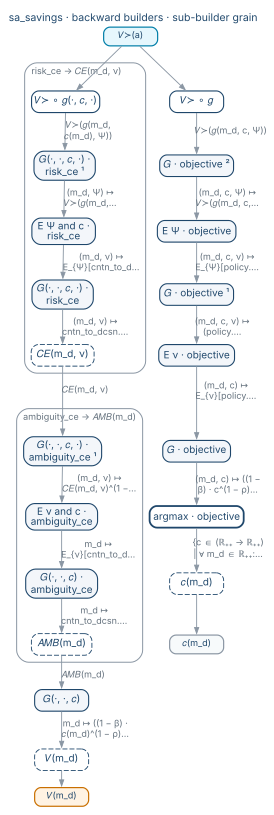

In [13]:
sa_savings.builder.bwd.sub_builders.diagram()

`checkout.explore` shows the backward builders graph in [Google's Model Explorer](https://github.com/google-ai-edge/model-explorer), an interactive viewer in which each builder is a frame opened to its operations and sub-builders, the decision builder's `risk_ce` and `ambiguity_ce` opening on a click to theirs, and in which selecting an operation shows, in a side panel, its kernel, its method once one is bound, and the wires it reads and writes, each with its perch and its type. The drawing above is the picture saved with the lesson, since the view opens only when the lesson is run: the saved output of the next cell is the paths of the two files it writes into the folder `model-explorer` beside the lesson.

In [14]:
checkout.explore(sa_savings)

tutorials/topics/model-explorer/sa_savings.graph.json
tutorials/topics/model-explorer/sa_savings.edge-overlays.json


## The card of the decision builder

The decision builder's card composes the pieces above. `At` names the consumption rule $c$ at which the operator is stated. Under `Operations`, each sub-builder heads the numbered entries it holds, and an entry reads after `in:` a wire or, by its number, an earlier entry. From $V_\succ$, the last entries of the two sub-builders write $\mathit{CE}$ and then $\mathit{AMB}$, and the last two entries of the card write $V$.

In [15]:
sa_savings.dcsn.builder.bwd.denote()

STAGE sa_savings / BACKWARD BUILDER cntn → dcsn (cntn_to_dcsn)
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
Signature
  in   𝑉≻  : ℝ₊₊ → ℝ₊₊
       ───────────────────────────────────────────────────────────────────
  out  𝑉   : ℝ₊₊ → ℝ₊₊

At
  𝑐  : ℝ₊₊ → ℝ₊₊,  𝑐(m_d) ∈ Γ(m_d)

Operations
      risk_ce
      in: 𝑉≻                            out: 𝐶𝐸
      ────────────────────────────────────────────────────────────────────
      rule: 𝐶𝐸 : ℝ₊₊ × ℝ → ℝ₊₊

   1    Pullback
        in: 𝑉≻                          out: 𝑉≻ ∘ 𝑔≻(·, 𝑐, ·)
        ──────────────────────────────────────────────────────────────────
        rule: (𝑉≻ ∘ 𝑔≻(·, 𝑐, ·))(m_d, Ψ) = 𝑉≻(𝑔≻(m_d, 𝑐(m_d), Ψ))

   2    Aggregation:1
        in: (1)
        out: (m_d, Ψ) ↦ 𝑉≻(𝑔≻(m_d, 𝑐(m_d), Ψ))^(1 − γ)
        ──────────────────────────────────────────────────────────────────
        rule: (m_d, Ψ) ↦ 𝑉≻(𝑔≻(m_d, 𝑐(m_d), Ψ))^(1 − γ)

   3    Expectation:1
        in: (2)                        

## One expectation over two shocks

The two expectations are taken one at a time because a nonlinear map stands between them: were $\eta$ equal to $\gamma$, the power $1-\eta$ would undo the root $1/(1-\gamma)$, and by the law of iterated expectations the two would be one expectation of $V_\succ(\mathrm a)^{1-\gamma}$ over the joint distribution of $\nu$ and $\Psi$; the declared set of $\eta$ includes that equality case. The portfolio stage of the portfolio–consumption model has such an expectation: its two shocks, the risky return and income, have one joint lognormal distribution, and its line `V = E_{Ψ,θ}(V[>])` integrates both at once. The next cell constructs that stage and prints the kernel of its value expectation.

In [16]:
elaborate_stage(load_stage("applications/portfolio-choice/declaration/stages/port/port.bl")).dcsn.builder.bwd["value:Expectation:1"].kernel()

distribution of (Ψ, θ): (Ψ, θ) ~ LogNormal((μ_Ψ, μ_θ), ((σ_Ψ^2, ρ_ζ*σ_Ψ*σ_θ), (ρ_ζ*σ_Ψ*σ_θ, σ_θ^2)))
conditioned on none declared; drawn on the edge dcsn_to_cntn; in cntn_to_dcsn at each point of k_d, integrates Ψ, θ; declared at port:distribution:Ψ_θ

One expectation, against a distribution conditioned on nothing, integrates both shocks at each level of the stage's capital $\mathrm k_d$.